# Step 13: final comparison
This notebook fits no model and only reads the saved scores of all models to build the final comparison tables and figures.

In [1]:
import sys, time, contextlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from tqdm import tqdm
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
SEED = 42
BOOT_B = 200
FAST = False
if FAST:
    BOOT_B = 50
TARGET_EPISODES = [10, 20, 40]
WINDOW_BEFORE = 12
WINDOW_AFTER = 5
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
C_SEP, C_CTL = "#d1495b", "#2e86ab"
pd.options.display.float_format = "{:.3f}".format
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

SUMMARY, SAVED = [], []
COUNT = {"pass": 0, "fail": 0}
DONE = set()


def log(text):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNT["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label} ({detail})")


def expect(label, observed, expected, tol=0):
    ok = abs(observed - expected) <= tol
    check(label, ok, f"observed {observed:.10g}, expected {expected:.10g}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


def depends(step, need):
    if need not in DONE:
        raise RuntimeError(f"{step} needs {need}, which did not finish. Fix that section and rerun from there.")


def save_fig(name):
    plt.tight_layout()
    p = FIG / name
    plt.savefig(p, dpi=150)
    SAVED.append(p)
    plt.show()
    plt.close()


def save_tab(df, name):
    p = TAB / name
    df.to_csv(p, index=False)
    SAVED.append(p)
    log(f"saved {name} ({len(df)} rows)")


def find_root():
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / "dataset").is_dir():
            return d
    raise FileNotFoundError(f"no folder with a dataset directory at or above {p}")

## Setup and input checks
Load the six score files and the patient splits and check that everything lines up. All later sections rely on these checks.

In [2]:
with timed("section 1"):
    ROOT = find_root()
    PROC, TAB, FIG, SRC = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures", ROOT / "src"
    TAB.mkdir(parents=True, exist_ok=True)
    FIG.mkdir(parents=True, exist_ok=True)
    sys.path.insert(0, str(SRC))
    import sepsis_eval as ev
    log(f"root: {ROOT}")

    GROUPS = {
        "m0_m3": ["M0_sirs", "M1_lr", "M2_dt", "M3_rf", "M3b_rf_all"],
        "m4_m6": ["M4_gnb_core", "M4b_bnb_masks", "M4c_gnb_pca", "M5_knn", "M6_linsvm", "M6_rbfsvm"],
        "m7": ["M7_mlp"],
    }
    ALL = [m for ms in GROUPS.values() for m in ms]
    MAIN = ["M0_sirs", "M1_lr", "M2_dt", "M3_rf", "M3b_rf_all", "M4_gnb_core", "M5_knn", "M6_rbfsvm", "M7_mlp"]
    KEYS = ["patient_id", "hour", "SepsisLabel"]
    EXP = {
        "val": dict(rows=234037, pos=4183, patients=6050, septic=440, first=65, never=5610),
        "test": dict(rows=232215, pos=4203, patients=6051, septic=440, first=63, never=5611),
    }

    def load_split(split):
        parts = {g: pd.read_parquet(PROC / f"scores_{g}_{split}.parquet") for g in GROUPS}
        base = parts["m0_m3"][KEYS].copy()
        base["patient_id"] = base["patient_id"].astype(str)
        ok_all = True
        for g, d in parts.items():
            same = len(d) == len(base)
            if same:
                same = bool((d["patient_id"].astype(str).to_numpy() == base["patient_id"].to_numpy()).all()
                            and (d["hour"].to_numpy() == base["hour"].to_numpy()).all()
                            and (d["SepsisLabel"].to_numpy() == base["SepsisLabel"].to_numpy()).all())
            have = all(m in d.columns for m in GROUPS[g])
            check(f"{split} scores_{g} aligned with scores_m0_m3", same and have, f"{len(d)} rows")
            ok_all = ok_all and same and have
        if not ok_all:
            raise RuntimeError(f"{split} score files do not align, stopping")
        cols = pd.DataFrame({m: parts[g][m].to_numpy(dtype=float) for g, ms in GROUPS.items() for m in ms})
        return pd.concat([base.reset_index(drop=True), cols], axis=1)

    BV, BT = load_split("val"), load_split("test")
    yv, yt = BV["SepsisLabel"].to_numpy().astype(int), BT["SepsisLabel"].to_numpy().astype(int)
    Sv, St = BV[ALL], BT[ALL]

    SP = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
    if not SP["patient_id"].is_unique:
        raise RuntimeError("patient_splits.csv has repeated patient_id values")

    def make_meta(base, split):
        m = base[["patient_id", "hour"]].merge(SP[["patient_id", "hospital", "ever_septic", "first_positive_hour"]],
                                                on="patient_id", how="left")
        miss = int(m["hospital"].isna().sum())
        check(f"{split} every row found in patient_splits", miss == 0, f"{miss} rows without a match")
        if miss or len(m) != len(base):
            raise RuntimeError(f"{split} meta merge failed")
        m["ever_septic"] = m["ever_septic"].astype(int)
        m["first_positive_hour"] = pd.to_numeric(m["first_positive_hour"], errors="coerce")
        return m

    Mv, Mt = make_meta(BV, "val"), make_meta(BT, "test")

    def group_sizes(meta):
        pt = meta.drop_duplicates("patient_id")
        sep = pt["ever_septic"] == 1
        return dict(patients=len(pt), septic=int(sep.sum()), first=int((sep & (pt["first_positive_hour"] == 0)).sum()),
                    never=int((~sep).sum()), early=int((sep & (pt["first_positive_hour"] > 0)).sum()))

    for split, y, meta in [("val", yv, Mv), ("test", yt, Mt)]:
        e, g = EXP[split], group_sizes(meta)
        with guarded(f"{split} size checks"):
            expect(f"{split} rows", len(y), e["rows"])
            expect(f"{split} positive rows", int(y.sum()), e["pos"])
            expect(f"{split} patients", g["patients"], e["patients"])
            expect(f"{split} septic patients", g["septic"], e["septic"])
            expect(f"{split} first-row septic patients", g["first"], e["first"])
            expect(f"{split} never-septic patients", g["never"], e["never"])
        log(f"{split} early-group septic patients: {g['early']}")
    with guarded("test early group size"):
        expect("test early-group septic patients", group_sizes(Mt)["early"], 377)
    with guarded("labels agree with ever_septic"):
        for split, base, meta in [("val", BV, Mv), ("test", BT, Mt)]:
            lab = base.groupby("patient_id")["SepsisLabel"].max()
            eps = meta.drop_duplicates("patient_id").set_index("patient_id")["ever_septic"]
            check(f"{split} patients with a label 1 equal ever_septic", np.array_equal(lab.reindex(eps.index).to_numpy(), eps.to_numpy()))
    log(f"test row positive rate: {yt.mean():.4f}")
    DONE.add("s1")

root: /Users/harnoorkaur/Downloads/Sepsis_ml
[PASS] val scores_m0_m3 aligned with scores_m0_m3 (234037 rows)
[PASS] val scores_m4_m6 aligned with scores_m0_m3 (234037 rows)
[PASS] val scores_m7 aligned with scores_m0_m3 (234037 rows)
[PASS] test scores_m0_m3 aligned with scores_m0_m3 (232215 rows)
[PASS] test scores_m4_m6 aligned with scores_m0_m3 (232215 rows)
[PASS] test scores_m7 aligned with scores_m0_m3 (232215 rows)
[PASS] val every row found in patient_splits (0 rows without a match)
[PASS] test every row found in patient_splits (0 rows without a match)
[PASS] val rows (observed 234037, expected 234037)
[PASS] val positive rows (observed 4183, expected 4183)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val septic patients (observed 440, expected 440)
[PASS] val first-row septic patients (observed 65, expected 65)
[PASS] val never-septic patients (observed 5610, expected 5610)
val early-group septic patients: 375
[PASS] test rows (observed 232215, expected 232215)
[P

## Thresholds and the main table
Thresholds are chosen on validation and applied to test. The tables report one row per model.

In [3]:
with timed("section 2"):
    depends("section 2", "s1")
    NFEAT = {"M1_lr": 50, "M3_rf": 50, "M3b_rf_all": 239, "M4_gnb_core": 50}
    COLS = ["model", "n_features", "threshold", "tp", "fp", "tn", "fn", "sensitivity", "specificity", "precision",
            "f1", "f2", "accuracy", "alert_rate", "auroc", "auprc"]
    THR = {m: 2.0 if m == "M0_sirs" else float(ev.best_f2_threshold(yv, Sv[m].to_numpy())) for m in ALL}
    rows = []
    for m in ALL:
        s = St[m].to_numpy()
        r = {"model": m, "n_features": NFEAT.get(m, np.nan), "threshold": THR[m]}
        r.update(ev.row_metrics(yt, s, THR[m]))
        r.update(ev.curve_metrics(yt, s))
        rows.append(r)
    EXT = pd.DataFrame(rows)[COLS]
    MAINT = EXT.set_index("model").loc[MAIN].reset_index()
    save_tab(EXT, "final_extended_table.csv")
    save_tab(MAINT, "final_main_table.csv")
    print(EXT.drop(columns=["tp", "fp", "tn", "fn"]).to_string(index=False))

    acc0 = 1 - yt.mean()
    log(f"accuracy of always predicting 0 on test: {acc0:.4f}")
    log("model accuracies on test: " + ", ".join(f"{m} {a:.4f}" for m, a in zip(EXT["model"], EXT["accuracy"])))

    def read_tab(name):
        p = TAB / name
        if not p.exists():
            log(f"earlier table {name} not found, skipped")
            return None
        try:
            return pd.read_csv(p)
        except Exception as e:
            log(f"earlier table {name} could not be read ({e}), skipped")
            return None

    def pick(df, key, exclude=("std",)):
        cols = [c for c in df.columns if c.lower() == key]
        cols += [c for c in df.columns if key in c.lower() and not any(x in c.lower() for x in exclude) and c not in cols]
        return cols[0] if cols else None

    def compare_test(name):
        df = read_tab(name)
        if df is None:
            return
        mc, ac, pc = pick(df, "model"), pick(df, "auroc"), pick(df, "auprc")
        if mc is None or ac is None or pc is None:
            log(f"{name}: model, auroc or auprc column not found, skipped")
            return
        E = EXT.set_index("model")
        hit = 0
        for _, r in df.iterrows():
            m = str(r[mc])
            if m in E.index:
                hit += 1
                with guarded(f"{name} {m} comparison"):
                    expect(f"{name} {m} auroc", float(E.loc[m, "auroc"]), float(r[ac]), 1e-6)
                    expect(f"{name} {m} auprc", float(E.loc[m, "auprc"]), float(r[pc]), 1e-6)
        if hit == 0:
            log(f"{name}: no model names matched, skipped")

    for name in ["m0_m3_results_test.csv", "m4_m6_results_test.csv", "ann_results_test.csv"]:
        compare_test(name)

    cv = {}
    for name in ["m0_m3_cv_summary.csv", "m4_cv_summary.csv"]:
        d = read_tab(name)
        if d is not None:
            mc, ac = pick(d, "model"), pick(d, "auroc_mean")
            if mc and ac:
                cv.update(dict(zip(d[mc].astype(str), d[ac])))
            else:
                log(f"{name}: model or auroc_mean column not found, skipped")
    d = read_tab("ann_cv_summary.csv")
    if d is not None:
        mc, ac = pick(d, "metric"), pick(d, "mean")
        v = d.loc[d[mc].astype(str).str.lower() == "auroc", ac] if mc and ac else []
        if len(v):
            cv["M7_mlp"] = float(v.iloc[0])
        else:
            log("ann_cv_summary.csv: auroc row not found, skipped")
    if cv:
        print(EXT[["model", "auroc"]].assign(cv_auroc_mean=EXT["model"].map(cv)).to_string(index=False))
    DONE.add("s2")

saved final_extended_table.csv (12 rows)
saved final_main_table.csv (9 rows)
        model  n_features  threshold  sensitivity  specificity  precision    f1    f2  accuracy  alert_rate  auroc  auprc
      M0_sirs         NaN      2.000        0.499        0.708      0.031 0.057 0.123     0.704       0.296  0.638  0.029
        M1_lr      50.000      0.716        0.409        0.925      0.091 0.149 0.241     0.915       0.081  0.787  0.098
        M2_dt         NaN      0.802        0.347        0.948      0.109 0.166 0.241     0.937       0.058  0.786  0.093
        M3_rf      50.000      0.615        0.447        0.931      0.107 0.172 0.273     0.922       0.076  0.833  0.108
   M3b_rf_all     239.000      0.603        0.440        0.940      0.118 0.186 0.285     0.930       0.067  0.844  0.114
  M4_gnb_core      50.000     12.423        0.353        0.948      0.111 0.169 0.246     0.937       0.057  0.757  0.082
M4b_bnb_masks         NaN     -3.931        0.395        0.800      0

## Patient-level bootstrap
Test patients are resampled with replacement and the same resample is used for every model. This gives intervals and paired differences.

test patients: 6051, bootstrap replicates: 200


bootstrap: 100%|██████████| 200/200 [02:29<00:00,  1.34it/s]


saved final_bootstrap_metrics.csv (9 rows)
saved final_main_table.csv (9 rows)
      model  auroc  auroc_low  auroc_high  auprc  auprc_low  auprc_high
    M0_sirs  0.638      0.618       0.657  0.029      0.026       0.033
      M1_lr  0.787      0.770       0.802  0.098      0.084       0.116
      M2_dt  0.786      0.768       0.803  0.093      0.080       0.111
      M3_rf  0.833      0.818       0.849  0.108      0.094       0.132
 M3b_rf_all  0.844      0.829       0.857  0.114      0.101       0.139
M4_gnb_core  0.757      0.736       0.778  0.082      0.073       0.099
     M5_knn  0.793      0.773       0.812  0.083      0.073       0.098
  M6_rbfsvm  0.813      0.797       0.828  0.081      0.070       0.095
     M7_mlp  0.819      0.804       0.835  0.110      0.096       0.131
saved final_bootstrap_paired_differences.csv (18 rows)
          a       b metric  mean_diff    low   high  share_of_replicates_a_better
      M1_lr M0_sirs  auroc      0.149  0.129  0.170             

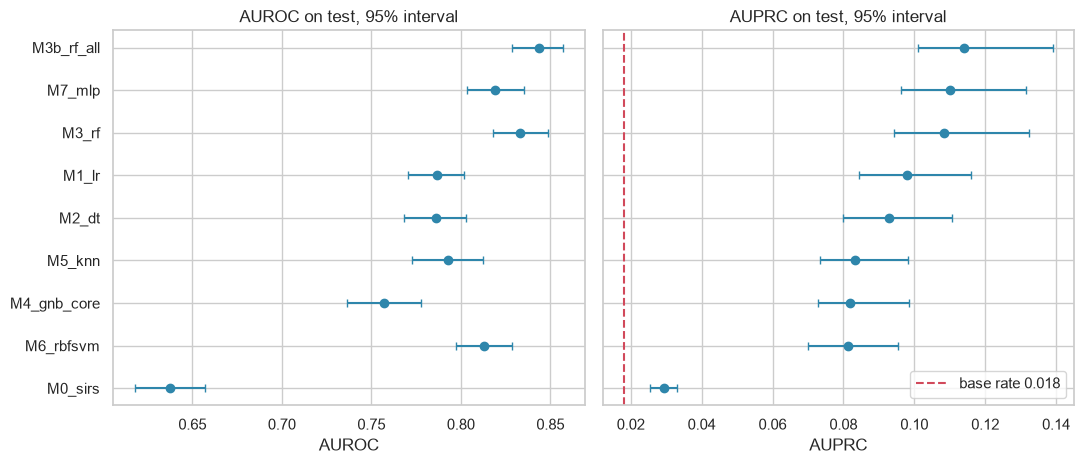

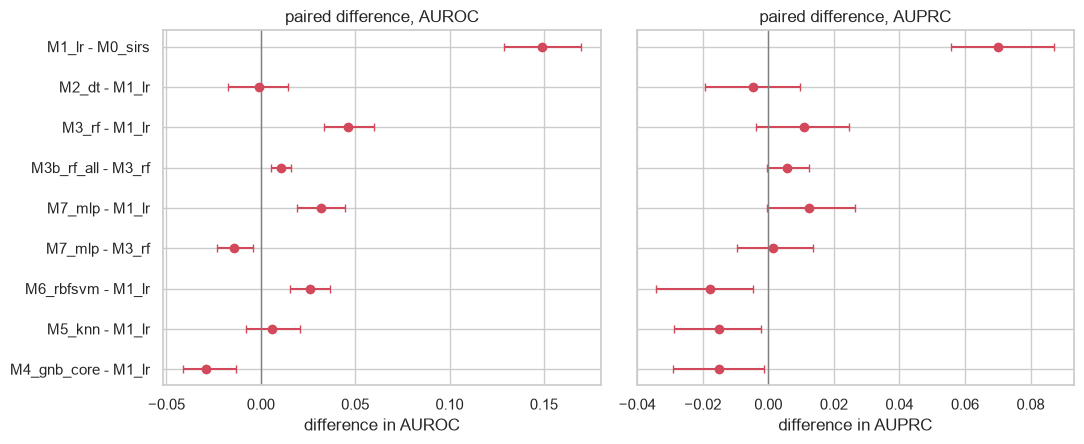

section 3: 150.2 s


In [4]:
with timed("section 3"):
    depends("section 3", "s2")
    codes_t, _ = pd.factorize(Mt["patient_id"])
    order = np.argsort(codes_t, kind="stable")
    IDX_T = np.split(order, np.cumsum(np.bincount(codes_t))[:-1])
    P_T = len(IDX_T)
    log(f"test patients: {P_T}, bootstrap replicates: {BOOT_B}")

    rng = np.random.default_rng(SEED)
    draws = rng.integers(0, P_T, size=(BOOT_B, P_T))
    ST = {m: St[m].to_numpy() for m in MAIN}
    BA = {m: np.zeros(BOOT_B) for m in MAIN}
    BP = {m: np.zeros(BOOT_B) for m in MAIN}
    for b in tqdm(range(BOOT_B), desc="bootstrap"):
        rows_b = np.concatenate([IDX_T[i] for i in draws[b]])
        yb = yt[rows_b]
        for m in MAIN:
            cm = ev.curve_metrics(yb, ST[m][rows_b])
            BA[m][b], BP[m][b] = cm["auroc"], cm["auprc"]

    pt_est = EXT.set_index("model")
    brow = []
    for m in MAIN:
        r = {"model": m}
        for k, arr in [("auroc", BA[m]), ("auprc", BP[m])]:
            lo, hi = np.percentile(arr, [2.5, 97.5])
            r.update({k: float(pt_est.loc[m, k]), k + "_low": float(lo), k + "_high": float(hi)})
        brow.append(r)
    BOOT = pd.DataFrame(brow)
    save_tab(BOOT, "final_bootstrap_metrics.csv")
    MAINT = MAINT.merge(BOOT.drop(columns=["auroc", "auprc"]), on="model", how="left")
    save_tab(MAINT, "final_main_table.csv")
    print(BOOT.to_string(index=False))

    PAIRS = [("M1_lr", "M0_sirs"), ("M2_dt", "M1_lr"), ("M3_rf", "M1_lr"), ("M3b_rf_all", "M3_rf"), ("M7_mlp", "M1_lr"),
             ("M7_mlp", "M3_rf"), ("M6_rbfsvm", "M1_lr"), ("M5_knn", "M1_lr"), ("M4_gnb_core", "M1_lr")]
    prow = []
    for a, b in PAIRS:
        for k, D in [("auroc", BA), ("auprc", BP)]:
            d = D[a] - D[b]
            lo, hi = np.percentile(d, [2.5, 97.5])
            prow.append({"a": a, "b": b, "metric": k, "mean_diff": float(d.mean()), "low": float(lo), "high": float(hi),
                         "share_of_replicates_a_better": float((d > 0).mean())})
    PD = pd.DataFrame(prow)
    save_tab(PD, "final_bootstrap_paired_differences.csv")
    print(PD.to_string(index=False))

    with guarded("bootstrap checks"):
        expect("bootstrap replicates", len(BA["M1_lr"]), BOOT_B)
        check("all replicate metrics are finite", all(np.isfinite(BA[m]).all() and np.isfinite(BP[m]).all() for m in MAIN))
        for k in ["auroc", "auprc"]:
            inside = ((BOOT[k] >= BOOT[k + "_low"]) & (BOOT[k] <= BOOT[k + "_high"]))
            check(f"every {k} point estimate lies inside its interval", inside.all(),
                  "outside: " + (", ".join(BOOT.loc[~inside, "model"]) or "none"))

    base_rate = yt.mean()
    order_m = BOOT.sort_values("auprc")["model"].tolist()
    Bi = BOOT.set_index("model").loc[order_m]
    yy = np.arange(len(order_m))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
    for ax, k in zip(axes, ["auroc", "auprc"]):
        xerr = [np.clip(Bi[k] - Bi[k + "_low"], 0, None), np.clip(Bi[k + "_high"] - Bi[k], 0, None)]
        ax.errorbar(Bi[k], yy, xerr=xerr, fmt="o", color=C_CTL, ecolor=C_CTL, capsize=3)
        ax.set_yticks(yy)
        ax.set_yticklabels(order_m)
        ax.set_xlabel(k.upper())
        ax.set_title(f"{k.upper()} on test, 95% interval")
    axes[1].axvline(base_rate, color=C_SEP, ls="--", label=f"base rate {base_rate:.3f}")
    axes[1].legend(loc="lower right")
    save_fig("fig13_main_table_cis.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    labels = [f"{a} - {b}" for a, b in PAIRS]
    yp = np.arange(len(PAIRS))[::-1]
    for ax, k in zip(axes, ["auroc", "auprc"]):
        d = PD[PD["metric"] == k]
        ax.errorbar(d["mean_diff"], yp, xerr=[d["mean_diff"] - d["low"], d["high"] - d["mean_diff"]], fmt="o",
                    color=C_SEP, ecolor=C_SEP, capsize=3)
        ax.axvline(0, color="grey", lw=1)
        ax.set_yticks(yp)
        ax.set_yticklabels(labels)
        ax.set_xlabel(f"difference in {k.upper()}")
        ax.set_title(f"paired difference, {k.upper()}")
    save_fig("fig13_paired_differences.png")
    DONE.add("s3")

## Timely-alert categories
Each early-group septic patient is put into one category from the hour of the first alert. Never-septic patients give the false alert numbers.

In [5]:
with timed("section 4"):
    depends("section 4", "s2")

    def first_alert(meta, score, thr):
        a = score >= thr
        h = np.where(a, meta["hour"].to_numpy(float), np.inf)
        return pd.Series(h).groupby(meta["patient_id"].to_numpy()).min()

    def timely_categories(meta, score, thr):
        fa = first_alert(meta, score, thr)
        pt = meta.drop_duplicates("patient_id").set_index("patient_id")
        early = pt[(pt["ever_septic"] == 1) & (pt["first_positive_hour"] > 0)]
        f = fa.reindex(early.index).to_numpy()
        t0 = early["first_positive_hour"].to_numpy(float)
        none = ~np.isfinite(f)
        too = f < t0 - WINDOW_BEFORE
        late = (f > t0 + WINDOW_AFTER) & ~none
        tim = ~none & ~too & ~late
        n = max(len(early), 1)
        am = ev.alert_metrics(meta, score, thr)
        return {"n_early": len(early), "share_too_early": too.sum() / n, "share_timely": tim.sum() / n,
                "share_late": late.sum() / n, "share_none": none.sum() / n,
                "median_lead_timely_h": float(np.median(t0[tim] - f[tim])) if tim.any() else np.nan,
                "share_nonseptic_ever_alerted": am["share_nonseptic_ever_alerted"],
                "false_alert_episodes_per_100_patient_days": am["false_alert_episodes_per_100_patient_days"],
                "share_alerted_by_first_label": am["share_alerted_by_first_label"],
                "share_alerted_any": am["share_alerted_any"],
                "share_alerted_any_first_row": am["share_alerted_any_first_row"]}

    St_arr = {m: St[m].to_numpy() for m in ALL}
    Sv_arr = {m: Sv[m].to_numpy() for m in ALL}
    trow = []
    for m in tqdm(ALL, desc="timely categories"):
        tc = timely_categories(Mt, St_arr[m], THR[m])
        trow.append({"model": m, "threshold": THR[m], **tc})
    TIM = pd.DataFrame(trow)
    TCOLS = ["model", "threshold", "share_too_early", "share_timely", "share_late", "share_none", "median_lead_timely_h",
             "share_nonseptic_ever_alerted", "false_alert_episodes_per_100_patient_days"]
    save_tab(TIM[TCOLS], "final_timely_alert_test.csv")
    print(TIM[TCOLS].to_string(index=False))

    with guarded("timely share checks"):
        tot = TIM[["share_too_early", "share_timely", "share_late", "share_none"]].sum(axis=1)
        check("four category shares add up to 1 for every model", np.allclose(tot, 1), f"max deviation {np.abs(tot - 1).max():.2e}")
        expect("early-group size on test", int(TIM["n_early"].iloc[0]), 377)
    for _, r in TIM.iterrows():
        rel = "larger than" if r["share_too_early"] > r["share_timely"] else ("smaller than" if r["share_too_early"] < r["share_timely"] else "equal to")
        log(f"{r['model']}: too_early {r['share_too_early']:.3f}, timely {r['share_timely']:.3f}, too_early is {rel} timely")
    DONE.add("s4")

timely categories: 100%|██████████| 12/12 [00:01<00:00, 11.20it/s]

saved final_timely_alert_test.csv (12 rows)
        model  threshold  share_too_early  share_timely  share_late  share_none  median_lead_timely_h  share_nonseptic_ever_alerted  false_alert_episodes_per_100_patient_days
      M0_sirs      2.000            0.599         0.286       0.037       0.077                 4.000                         0.730                                    172.729
        M1_lr      0.716            0.414         0.194       0.037       0.355                 0.000                         0.151                                     26.514
        M2_dt      0.802            0.369         0.164       0.045       0.422                 3.000                         0.141                                     15.789
        M3_rf      0.615            0.430         0.204       0.029       0.337                 3.000                         0.130                                     18.386
   M3b_rf_all      0.603            0.419         0.199       0.024       0.358  

## Matched false-alarm operating points
Thresholds are found on validation so that the false alert rate stays at or below each target, then applied to test unchanged. A threshold sweep shows the trade-off.

matched operating points: 100%|██████████| 9/9 [00:09<00:00,  1.11s/it]


saved final_operating_points_test.csv (27 rows)
      model  target_episodes  threshold  val_false_episodes  test_false_episodes  test_sensitivity  test_specificity  test_precision  share_too_early  share_timely  share_late  share_none  share_alerted_by_first_label  share_alerted_any  share_nonseptic_ever_alerted  share_alerted_any_first_row
    M0_sirs               10      4.000               6.074                6.567             0.032             0.991           0.062            0.117         0.058       0.021       0.804                         0.151              0.196                         0.065                        0.063
    M0_sirs               20      4.000               6.074                6.567             0.032             0.991           0.062            0.117         0.058       0.021       0.804                         0.151              0.196                         0.065                        0.063
    M0_sirs               40      4.000               6.074     

trade-off sweep: 100%|██████████| 9/9 [00:10<00:00,  1.19s/it]


saved final_alert_tradeoff_test.csv (123 rows)
saved rq3_threshold_sweep_test.csv (60 rows)
     model  threshold   tp    fp     tn   fn  sensitivity  specificity  precision    f1    f2  accuracy  alert_rate
     M1_lr      0.548 2579 42838 185174 1624        0.614        0.812      0.057 0.104 0.207     0.809       0.196
     M1_lr      0.564 2504 39604 188408 1699        0.596        0.826      0.059 0.108 0.212     0.822       0.181
     M1_lr      0.581 2432 36455 191557 1771        0.579        0.840      0.063 0.113 0.218     0.835       0.167
     M1_lr      0.599 2344 33320 194692 1859        0.558        0.854      0.066 0.118 0.223     0.849       0.154
     M1_lr      0.619 2233 30150 197862 1970        0.531        0.868      0.069 0.122 0.227     0.862       0.139
     M1_lr      0.640 2102 26810 201202 2101        0.500        0.882      0.073 0.127 0.230     0.875       0.125
     M1_lr      0.662 1960 23637 204375 2243        0.466        0.896      0.077 0.132 0.231   

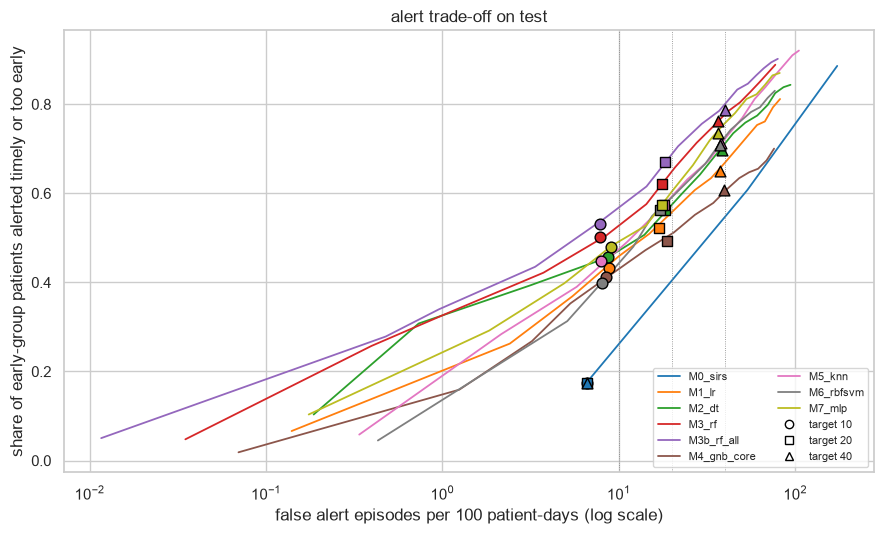

section 5: 21.4 s


In [6]:
with timed("section 5"):
    depends("section 5", "s4")
    RATE, CAND = {}, {}

    def val_rate(m, thr):
        k = (m, float(thr))
        if k not in RATE:
            RATE[k] = ev.alert_metrics(Mv, Sv_arr[m], thr)["false_alert_episodes_per_100_patient_days"]
        return RATE[k]

    def candidates(m):
        if m not in CAND:
            if m == "M0_sirs":
                CAND[m] = np.array([1.0, 2.0, 3.0, 4.0])
            else:
                sv = Sv_arr[m]
                q = np.unique(np.concatenate([np.linspace(0, 0.99, 300), 1 - np.geomspace(0.01, 1.0 / len(sv), 700)]))
                CAND[m] = np.unique(np.quantile(sv, np.clip(q, 0, 1), method="lower"))
        return CAND[m]

    def find_thr(m, target):
        c = candidates(m)
        if val_rate(m, c[-1]) > target:
            return np.nan
        lo, hi = 0, len(c) - 1
        while lo < hi:
            mid = (lo + hi) // 2
            if val_rate(m, c[mid]) <= target:
                hi = mid
            else:
                lo = mid + 1
        return float(c[lo])

    OPCOLS = ["model", "target_episodes", "threshold", "val_false_episodes", "test_false_episodes", "test_sensitivity",
              "test_specificity", "test_precision", "share_too_early", "share_timely", "share_late", "share_none",
              "share_alerted_by_first_label", "share_alerted_any", "share_nonseptic_ever_alerted", "share_alerted_any_first_row"]
    OP = []
    for m in tqdm(MAIN, desc="matched operating points"):
        for tg in TARGET_EPISODES:
            thr = find_thr(m, tg)
            r = {"model": m, "target_episodes": tg, "threshold": thr}
            if np.isnan(thr):
                log(f"{m}: no threshold reaches {tg} false alert episodes per 100 patient-days on val (NaN)")
            else:
                rm = ev.row_metrics(yt, St_arr[m], thr)
                tc = timely_categories(Mt, St_arr[m], thr)
                r.update({"val_false_episodes": val_rate(m, thr),
                          "test_false_episodes": tc["false_alert_episodes_per_100_patient_days"],
                          "test_sensitivity": rm["sensitivity"], "test_specificity": rm["specificity"],
                          "test_precision": rm["precision"]})
                r.update({k: tc[k] for k in OPCOLS if k.startswith("share_")})
            OP.append(r)
    OPD = pd.DataFrame(OP, columns=OPCOLS)
    save_tab(OPD, "final_operating_points_test.csv")
    print(OPD.to_string(index=False))
    with guarded("matched threshold checks"):
        ok = OPD.dropna(subset=["threshold"])
        check("validation false alert rate is at or below its target", (ok["val_false_episodes"] <= ok["target_episodes"] + 1e-9).all(),
              f"{len(ok)} of {len(OPD)} operating points found")

    QS = np.linspace(0.80, 0.999, 15)
    SW = []
    for m in tqdm(MAIN, desc="trade-off sweep"):
        for thr in np.unique(np.quantile(Sv_arr[m], QS, method="lower")):
            rm = ev.row_metrics(yt, St_arr[m], thr)
            tc = timely_categories(Mt, St_arr[m], thr)
            SW.append({"model": m, "threshold": float(thr), **rm,
                       "false_alert_episodes_per_100_patient_days": tc["false_alert_episodes_per_100_patient_days"],
                       "share_timely": tc["share_timely"],
                       "share_timely_or_too_early": tc["share_timely"] + tc["share_too_early"],
                       "share_alerted_any": tc["share_alerted_any"]})
    SWD = pd.DataFrame(SW)
    TRAD = SWD[["model", "threshold", "false_alert_episodes_per_100_patient_days", "share_timely", "share_timely_or_too_early",
                "share_alerted_any", "sensitivity", "precision"]]
    save_tab(TRAD, "final_alert_tradeoff_test.csv")
    RQ3 = SWD[SWD["model"].isin(["M1_lr", "M3_rf", "M3b_rf_all", "M7_mlp"])][
        ["model", "threshold", "tp", "fp", "tn", "fn", "sensitivity", "specificity", "precision", "f1", "f2", "accuracy", "alert_rate"]]
    save_tab(RQ3, "rq3_threshold_sweep_test.csv")
    print(RQ3.to_string(index=False))

    pal = dict(zip(MAIN, sns.color_palette("tab10", len(MAIN))))
    marks = ["o", "s", "^", "D", "v"]
    xcol = "false_alert_episodes_per_100_patient_days"
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for m in MAIN:
        d = TRAD[(TRAD["model"] == m) & (TRAD[xcol] > 0)].sort_values(xcol)
        ax.plot(d[xcol], d["share_timely_or_too_early"], "-", color=pal[m], lw=1.3, label=m)
    for i, tg in enumerate(TARGET_EPISODES):
        ax.axvline(tg, color="grey", lw=0.6, ls=":")
        d = OPD[(OPD["target_episodes"] == tg) & (OPD["test_false_episodes"] > 0)]
        for _, r in d.iterrows():
            ax.scatter(r["test_false_episodes"], r["share_timely"] + r["share_too_early"], marker=marks[i % len(marks)],
                       s=60, color=pal[r["model"]], edgecolor="black", zorder=5)
    handles, labs = ax.get_legend_handles_labels()
    handles += [Line2D([], [], marker=marks[i % len(marks)], ls="", color="white", markeredgecolor="black", label=f"target {tg}")
                for i, tg in enumerate(TARGET_EPISODES)]
    ax.legend(handles=handles, fontsize=8, ncol=2, loc="lower right")
    ax.set_xscale("log")
    ax.set_xlabel("false alert episodes per 100 patient-days (log scale)")
    ax.set_ylabel("share of early-group patients alerted timely or too early")
    ax.set_title("alert trade-off on test")
    save_fig("fig13_alert_tradeoff.png")
    DONE.add("s5")

## Calibration
Raw scores are not probabilities, so they are compared with an isotonic recalibration fitted on validation. Everything is reported on test.

M1_lr: test AUROC raw 0.7865, isotonic 0.7859
M3_rf: test AUROC raw 0.8332, isotonic 0.8325
M3b_rf_all: test AUROC raw 0.8437, isotonic 0.8435
M7_mlp: test AUROC raw 0.8191, isotonic 0.8185
saved final_calibration_summary.csv (8 rows)
     model  version  brier  log_loss   ece  mean_pred  base_rate  auroc
     M1_lr      raw  0.182     0.557 0.368      0.386      0.018  0.787
     M1_lr isotonic  0.017     0.079 0.001      0.018      0.018  0.786
     M3_rf      raw  0.120     0.394 0.270      0.288      0.018  0.833
     M3_rf isotonic  0.017     0.075 0.001      0.017      0.018  0.833
M3b_rf_all      raw  0.105     0.356 0.244      0.262      0.018  0.844
M3b_rf_all isotonic  0.017     0.074 0.001      0.018      0.018  0.844
    M7_mlp      raw  0.052     0.200 0.131      0.149      0.018  0.819
    M7_mlp isotonic  0.017     0.078 0.001      0.018      0.018  0.818
[PASS] isotonic changes test AUROC by at most 0.02 (largest change 0.0006)


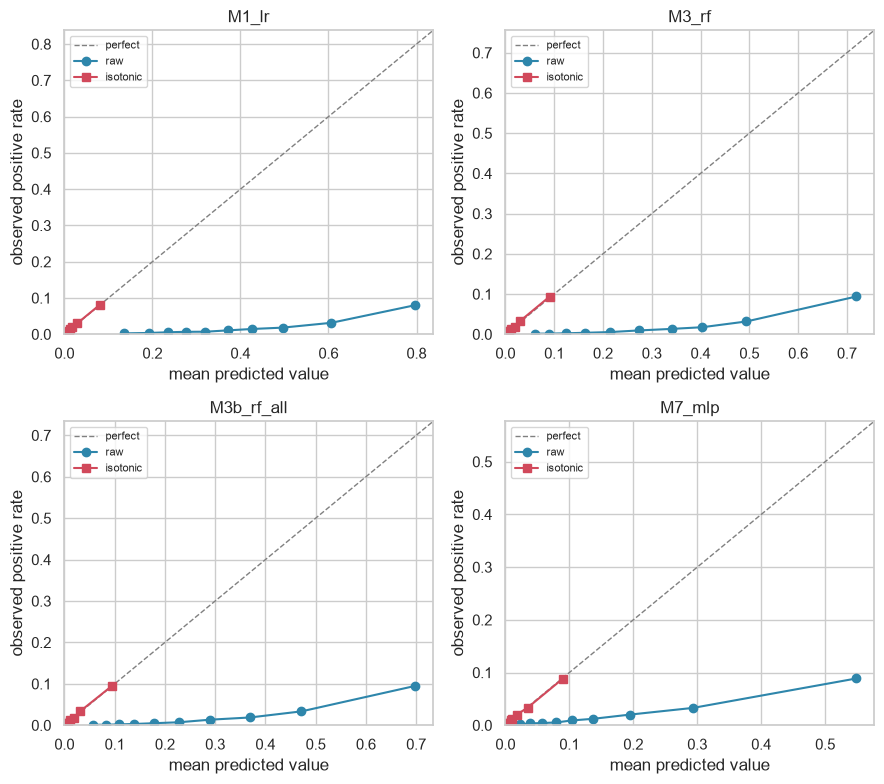

section 6: 1.9 s


In [7]:
with timed("section 6"):
    depends("section 6", "s2")
    CAL = ["M1_lr", "M3_rf", "M3b_rf_all", "M7_mlp"]

    def reliab(y, p):
        b = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False).to_numpy()
        return pd.DataFrame({"p": p, "y": y, "b": b}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))

    def calib_row(y, p, model, version):
        d = reliab(y, p)
        inside = p.min() >= 0 and p.max() <= 1
        pc = np.clip(p, 1e-15, 1 - 1e-15)
        return {"model": model, "version": version, "brier": float(np.mean((p - y) ** 2)),
                "log_loss": float(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))) if inside else np.nan,
                "ece": float((d["n"] / len(y) * (d["y"] - d["p"]).abs()).sum()), "mean_pred": float(p.mean()),
                "base_rate": float(y.mean()), "auroc": float(roc_auc_score(y, p))}

    crow, REL = [], {}
    for m in CAL:
        sv, st = Sv_arr[m], St_arr[m]
        iso = IsotonicRegression(out_of_bounds="clip").fit(sv, yv.astype(float))
        pi = iso.predict(st)
        crow += [calib_row(yt, st, m, "raw"), calib_row(yt, pi, m, "isotonic")]
        REL[m] = (reliab(yt, st), reliab(yt, pi))
        if not (st.min() >= 0 and st.max() <= 1):
            log(f"{m}: raw scores outside [0, 1], log loss skipped for raw")
        log(f"{m}: test AUROC raw {crow[-2]['auroc']:.4f}, isotonic {crow[-1]['auroc']:.4f}")
    CALD = pd.DataFrame(crow)
    save_tab(CALD, "final_calibration_summary.csv")
    print(CALD.to_string(index=False))
    with guarded("isotonic keeps the ranking"):
        g = CALD.pivot(index="model", columns="version", values="auroc")
        check("isotonic changes test AUROC by at most 0.02", ((g["raw"] - g["isotonic"]).abs() <= 0.02).all(),
              f"largest change {(g['raw'] - g['isotonic']).abs().max():.4f}")

    fig, axes = plt.subplots(2, 2, figsize=(9, 8))
    for ax, m in zip(axes.ravel(), CAL):
        raw, isr = REL[m]
        lim = min(1.0, 1.05 * max(raw["p"].max(), raw["y"].max(), isr["p"].max(), isr["y"].max()))
        ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=1, label="perfect")
        ax.plot(raw["p"], raw["y"], "o-", color=C_CTL, label="raw")
        ax.plot(isr["p"], isr["y"], "s-", color=C_SEP, label="isotonic")
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(m)
        ax.set_xlabel("mean predicted value")
        ax.set_ylabel("observed positive rate")
        ax.legend(fontsize=8)
    save_fig("fig13_calibration.png")
    DONE.add("s6")

## Curves and confusion matrices
PR and ROC curves for the main models, and confusion matrices for the random forest on all features and the neural network.

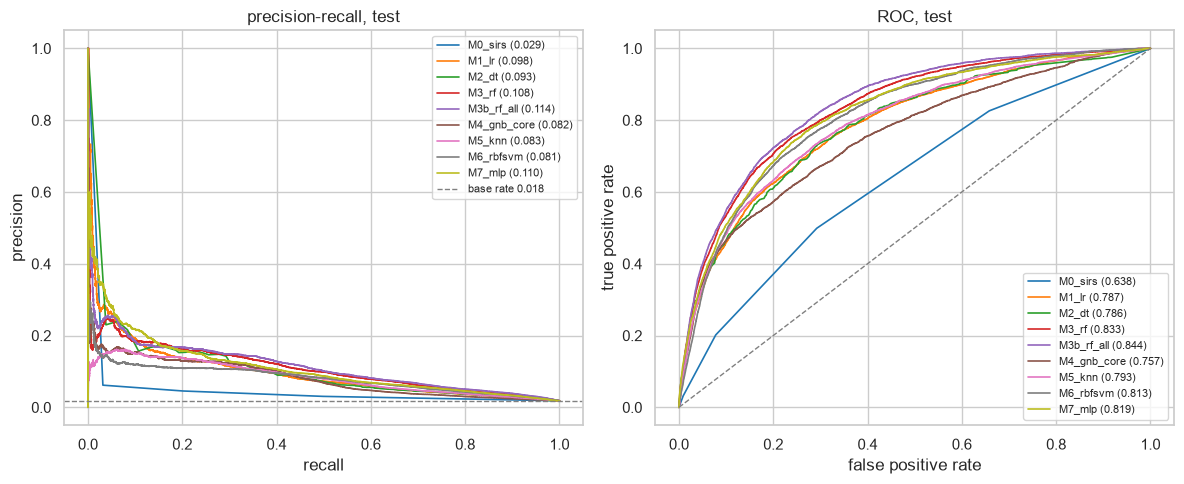

[PASS] M3b_rf_all confusion matrix total (observed 232215, expected 232215)
[PASS] M7_mlp confusion matrix total (observed 232215, expected 232215)


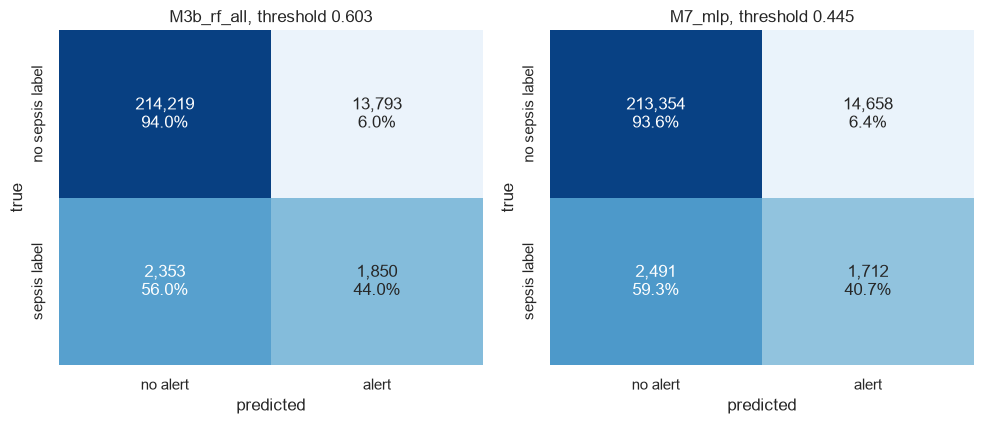

section 7: 2.3 s


In [8]:
with timed("section 7"):
    depends("section 7", "s2")
    E = EXT.set_index("model")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for m in MAIN:
        s = St_arr[m]
        pr, rc, _ = precision_recall_curve(yt, s)
        fp_, tp_, _ = roc_curve(yt, s)
        axes[0].plot(rc, pr, color=pal[m], lw=1.2, label=f"{m} ({E.loc[m, 'auprc']:.3f})")
        axes[1].plot(fp_, tp_, color=pal[m], lw=1.2, label=f"{m} ({E.loc[m, 'auroc']:.3f})")
    axes[0].axhline(yt.mean(), color="grey", ls="--", lw=1, label=f"base rate {yt.mean():.3f}")
    axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
    axes[0].set(xlabel="recall", ylabel="precision", title="precision-recall, test")
    axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC, test")
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8, loc="lower right")
    save_fig("fig13_pr_roc_all_test.png")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    for ax, m in zip(axes, ["M3b_rf_all", "M7_mlp"]):
        r = E.loc[m]
        cm = np.array([[int(r["tn"]), int(r["fp"])], [int(r["fn"]), int(r["tp"])]])
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
        annot = [[f"{cm[i, j]:,}\n{pct[i, j]:.1f}%" for j in range(2)] for i in range(2)]
        sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                    xticklabels=["no alert", "alert"], yticklabels=["no sepsis label", "sepsis label"])
        ax.set_title(f"{m}, threshold {THR[m]:.3f}")
        ax.set_xlabel("predicted")
        ax.set_ylabel("true")
        with guarded(f"{m} confusion total"):
            expect(f"{m} confusion matrix total", int(cm.sum()), len(yt))
    save_fig("fig13_confusion_best.png")
    DONE.add("s7")

## Results index and output files
List every result file, report the files saved here and write the summary.

In [9]:
with timed("section 8"):
    RES = ROOT / "results"
    irows = []
    for kind, folder in [("table", TAB), ("figure", FIG)]:
        for p in sorted(folder.rglob("*")):
            if p.is_file():
                st_ = p.stat()
                irows.append({"path": p.relative_to(ROOT).as_posix(), "kind": kind, "size_kb": round(st_.st_size / 1024, 1),
                              "modified": time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(st_.st_mtime))})
    IDX = pd.DataFrame(irows, columns=["path", "kind", "size_kb", "modified"])
    p_idx = RES / "results_index.csv"
    IDX.to_csv(p_idx, index=False)
    SAVED.append(p_idx)
    log(f"results index: {len(IDX)} files listed in {p_idx.name}")

    for p in dict.fromkeys(SAVED):
        if p.exists():
            log(f"saved {p.relative_to(ROOT).as_posix()}  {p.stat().st_size / 1024:.1f} KB")
        else:
            log(f"MISSING {p.relative_to(ROOT).as_posix()}")

    log(f"checks: {COUNT['pass']} passed, {COUNT['fail']} failed")
    out = RES / "step13_summary.txt"
    out.write_text("\n".join(SUMMARY) + "\n", encoding="utf-8")
    print(out)

results index: 153 files listed in results_index.csv
saved results/tables/final_extended_table.csv  2.8 KB
saved results/tables/final_main_table.csv  2.8 KB
saved results/tables/final_bootstrap_metrics.csv  1.2 KB
saved results/tables/final_bootstrap_paired_differences.csv  1.6 KB
saved results/figures/fig13_main_table_cis.png  59.9 KB
saved results/figures/fig13_paired_differences.png  58.3 KB
saved results/tables/final_timely_alert_test.csv  1.9 KB
saved results/tables/final_operating_points_test.csv  7.6 KB
saved results/tables/final_alert_tradeoff_test.csv  17.2 KB
saved results/tables/rq3_threshold_sweep_test.csv  10.9 KB
saved results/figures/fig13_alert_tradeoff.png  164.2 KB
saved results/tables/final_calibration_summary.csv  1.1 KB
saved results/figures/fig13_calibration.png  150.9 KB
saved results/figures/fig13_pr_roc_all_test.png  198.1 KB
saved results/figures/fig13_confusion_best.png  71.2 KB
saved results/results_index.csv  10.7 KB
checks: 57 passed, 0 failed
/Users/harno